In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
file_path = "../data/processed/nse_stocks_processed.csv"

df = pd.read_csv(file_path)

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,symbol,open,high,low,close,adj_close,volume,daily_return,log_return,...,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,HDFCBANK,352.737488,355.000000,352.637512,354.149994,322.995026,4271860,0.004182,0.004174,...,326.772249,0.034354,0.070173,0.163776,0.021930,0.081209,0.0,26102606.8,0.163656,0.043742
1,2017-03-16,HDFCBANK,354.524994,355.712494,353.412506,354.337494,323.166046,4980108,0.000529,0.000529,...,327.873499,0.043742,0.070415,0.163818,0.018065,0.081039,0.0,26229309.2,0.189868,0.041542
2,2017-03-17,HDFCBANK,354.637512,356.875000,353.212494,356.462494,325.104065,3390464,0.005997,0.005979,...,329.053248,0.041542,0.044430,0.163148,0.022701,0.078392,0.0,26092485.4,0.129940,0.045417
3,2017-03-20,HDFCBANK,356.662506,359.962494,356.487488,359.024994,327.441101,8142344,0.007189,0.007163,...,330.306248,0.045417,0.036086,0.163586,0.025712,0.081482,0.0,26247417.6,0.310215,0.040547
4,2017-03-21,HDFCBANK,358.500000,361.250000,358.500000,360.237488,328.546997,5557280,0.003377,0.003371,...,331.579998,0.040547,0.035479,0.109982,0.021443,0.046403,0.0,6412283.6,0.866662,0.089630


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nStocks:")
print(df["symbol"].unique())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Shape: (18744, 25)

Columns:
['date', 'symbol', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'volume_ma_20', 'volume_ratio', 'target_5d_volatility']

Stocks:
['HDFCBANK' 'ICICIBANK' 'INFY' 'ITC' 'LT' 'RELIANCE' 'SBIN' 'TCS']

Missing Values:
0


In [4]:
features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5",
    "volatility_10",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "drawdown"
]

features = [
    col for col in features
    if col in df.columns
]

target = "target_5d_volatility"

print("Features:")
print(features)

print("\nTarget:", target)

Features:
['daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'drawdown']

Target: target_5d_volatility


In [5]:
model_df = df[
    ["date", "symbol"] + features + [target]
].copy()

model_df = model_df.dropna()

model_df = model_df.sort_values(
    ["symbol", "date"]
).reset_index(drop=True)

print("Model Dataset Shape:", model_df.shape)
model_df.head()

Model Dataset Shape: (18744, 12)


,date,symbol,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,drawdown,target_5d_volatility
0,2017-03-15,HDFCBANK,0.004182,0.004174,0.004004,0.006671,350.689990,348.237494,345.869373,326.772249,0.0,0.043742
1,2017-03-16,HDFCBANK,0.000529,0.000529,-0.000529,0.006491,351.947491,348.879993,347.197498,327.873499,0.0,0.041542
2,2017-03-17,HDFCBANK,0.005997,0.005979,0.005146,0.010275,353.529993,350.023743,348.493123,329.053248,0.0,0.045417
3,2017-03-20,HDFCBANK,0.007189,0.007163,0.006624,0.009679,355.329993,351.501242,349.845622,330.306248,0.0,0.040547
4,2017-03-21,HDFCBANK,0.003377,0.003371,0.004847,0.007634,356.842493,353.006241,350.644371,331.579998,0.0,0.089630


In [6]:
print(model_df[target].describe())

count    18744.000000
mean         0.223860
std          0.149638
min          0.016310
25%          0.132857
50%          0.189265
75%          0.269226
max          1.852513
Name: target_5d_volatility, dtype: float64


In [7]:
train_parts = []
test_parts = []

for symbol, stock_data in model_df.groupby("symbol"):

    stock_data = stock_data.sort_values("date")

    split_index = int(len(stock_data) * 0.80)

    train_parts.append(
        stock_data.iloc[:split_index]
    )

    test_parts.append(
        stock_data.iloc[split_index:]
    )

train_df = pd.concat(train_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print("Training Rows:", len(train_df))
print("Testing Rows:", len(test_df))

Training Rows: 14992
Testing Rows: 3752


In [8]:
print("Training Date Range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting Date Range:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training Date Range:
2017-03-15 00:00:00 to 2024-10-15 00:00:00

Testing Date Range:
2024-10-16 00:00:00 to 2026-09-01 00:00:00


In [9]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (14992, 9)
X_test: (3752, 9)


In [10]:
baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.09506911066898731
Baseline RMSE: 0.11750054871231588


In [11]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 0.07321850309447238
Linear Regression RMSE: 0.09598478243016917


In [12]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    by="coefficient",
    key=abs,
    ascending=False
)

coefficients

,feature,coefficient
0,daily_return,50.213543
1,log_return,-49.706203
3,price_range,5.898799
2,intraday_return,-0.509642
8,drawdown,-0.158039
7,ma_50,0.000141
5,ma_10,-0.000107
6,ma_20,-0.000086
4,ma_5,0.000051


In [13]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.07445237147304942
Random Forest RMSE: 0.09923546153032993


In [14]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

results

,Model,MAE,RMSE
0,Baseline,0.095069,0.117501
1,Linear Regression,0.073219,0.095985
2,Random Forest,0.074452,0.099235


In [15]:
results_path = "../data/processed/nse_stocks_initial_model_results.csv"

results.to_csv(
    results_path,
    index=False
)

print("Model results saved successfully!")
print(results_path)

Model results saved successfully!
../data/processed/nse_stocks_initial_model_results.csv


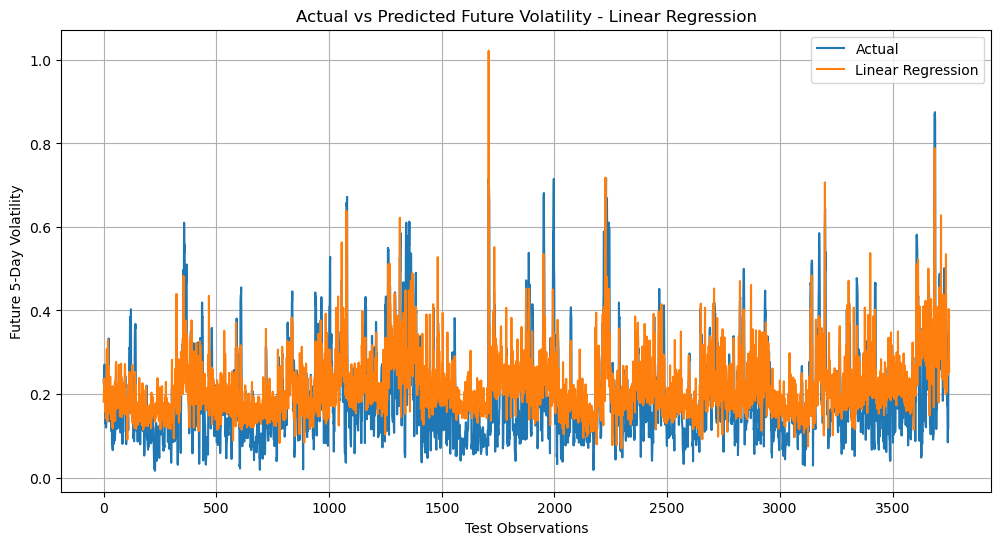

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    linear_predictions,
    label="Linear Regression"
)

plt.title("Actual vs Predicted Future Volatility - Linear Regression")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

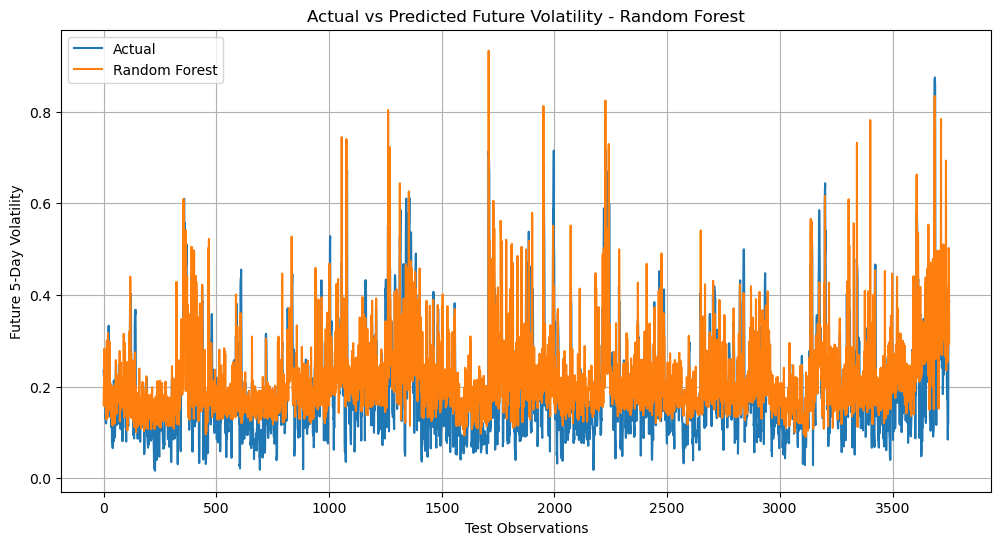

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    rf_predictions,
    label="Random Forest"
)

plt.title("Actual vs Predicted Future Volatility - Random Forest")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
3,price_range,0.498711
8,drawdown,0.108895
2,intraday_return,0.073038
0,daily_return,0.066806
1,log_return,0.066223
7,ma_50,0.059275
4,ma_5,0.045680
6,ma_20,0.042821
5,ma_10,0.038552


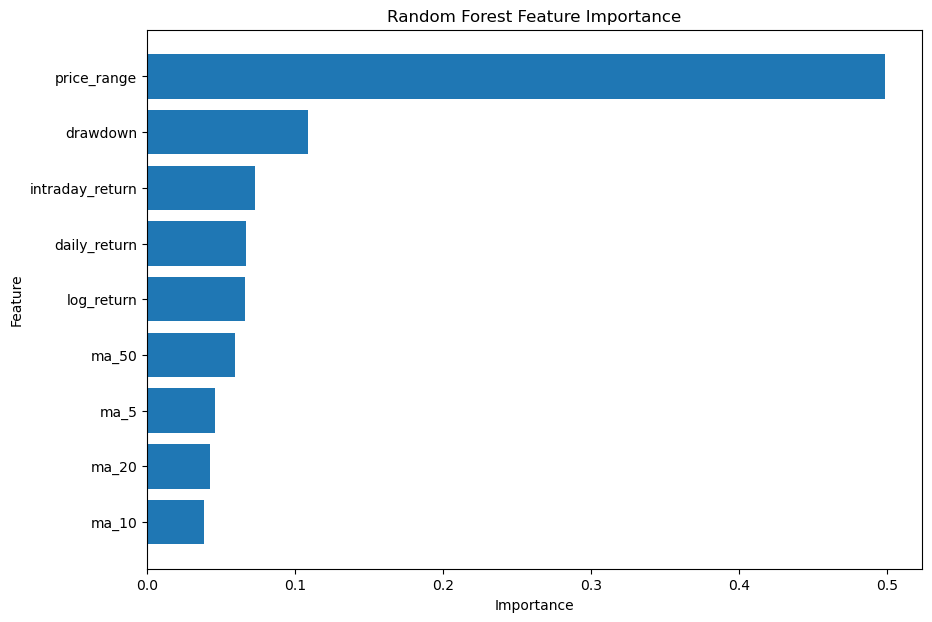

In [19]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [20]:
importance_path = "../data/processed/nse_stocks_random_forest_feature_importance.csv"

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved successfully!")
print(importance_path)

Feature importance saved successfully!
../data/processed/nse_stocks_random_forest_feature_importance.csv


In [21]:
stock_results = []

for symbol in test_df["symbol"].unique():

    mask = test_df["symbol"] == symbol

    actual = y_test[mask]
    predicted = rf_predictions[mask]

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    stock_results.append({
        "symbol": symbol,
        "MAE": mae,
        "RMSE": rmse,
        "test_rows": mask.sum()
    })

stock_results_df = pd.DataFrame(stock_results)

stock_results_df

,symbol,MAE,RMSE,test_rows
0,HDFCBANK,0.063389,0.083125,469
1,ICICIBANK,0.056347,0.070883,469
2,INFY,0.089782,0.117037,469
3,ITC,0.083577,0.109203,469
4,LT,0.078053,0.106765,469
5,RELIANCE,0.060958,0.077808,469
6,SBIN,0.068228,0.090239,469
7,TCS,0.095284,0.125013,469


In [22]:
stock_results_path = "../data/processed/nse_stocks_model_results_by_stock.csv"

stock_results_df.to_csv(
    stock_results_path,
    index=False
)

print("Stock-wise model results saved!")
print(stock_results_path)

Stock-wise model results saved!
../data/processed/nse_stocks_model_results_by_stock.csv


In [23]:
print("NSE STOCKS INITIAL MODEL EXPERIMENT")
print("-----------------------------------")

print("\nModels Tested:")
print("1. Baseline")
print("2. Linear Regression")
print("3. Random Forest")

print("\nEvaluation Metrics:")
print("1. MAE")
print("2. RMSE")

print("\nTarget:")
print(target)

print("\nTraining Rows:", len(train_df))
print("Testing Rows:", len(test_df))

NSE STOCKS INITIAL MODEL EXPERIMENT
-----------------------------------

Models Tested:
1. Baseline
2. Linear Regression
3. Random Forest

Evaluation Metrics:
1. MAE
2. RMSE

Target:
target_5d_volatility

Training Rows: 14992
Testing Rows: 3752


In [24]:
results

,Model,MAE,RMSE
0,Baseline,0.095069,0.117501
1,Linear Regression,0.073219,0.095985
2,Random Forest,0.074452,0.099235
